# Expert-reference evaluation and calibration
Reproduce the plots and tables from the LLM-selection, weight and penalty notebooks in manuscript order (Sections 4.3.3-4.3.5). The fixed 320 expert-reference instances were sampled from the preceding experiment's 4,781 context-bearing citation pairs, using pre-annotation cross-encoder score intervals. This notebook does not resample labels, call models/APIs, or access/write the database.

Run from src/ or the repository root. Dependencies: numpy, pandas, scipy, scikit-learn, matplotlib, openpyxl, python-dotenv, IPython. SEED must be supplied through the environment or the existing local .env; no default is defined. Original input files and notebooks are preserved. Stable derived outputs are replaced under sample/expert_evaluation/.

Inputs: expert_label.xlsx, sample/llms_scored.xlsx, sample/abstract_only_scores.xlsx. Set INPUT_DIR below to the exported numeric_inputs directory to reproduce all analyses using CSVs without source texts. Paired IDs are retained for alignment and shared-paper grouping, but texts, titles, reasons, raw responses and annotator identities are not exported.

This is a curated human-reference subset, not an independent external test set. Bootstrap intervals condition on saved predictions; the abstract-only experiment is controlled context masking, not validation on naturally missing-context cases.

## 1. Configuration
Load the environment seed once and define stable output paths. No paid inference or database access is performed.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, cohen_kappa_score, confusion_matrix
from typing import Any
from decimal import Decimal, ROUND_HALF_UP

def paper_number(value, digits=4):
    # Conventional decimal half-up rounding, without binary floating-point tie noise.
    return format(Decimal(format(float(value), '.15g')).quantize(
        Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP), f'.{digits}f')
from pathlib import Path
from datetime import datetime, timezone
from itertools import combinations
import hashlib, importlib.metadata, json, os, subprocess
from IPython.display import display
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedGroupKFold
from dotenv import load_dotenv
SRC_DIR = Path.cwd().resolve()
if not (SRC_DIR / 'expert_evaluation.ipynb').is_file():
    SRC_DIR = SRC_DIR / 'src'
if not (SRC_DIR / 'expert_evaluation.ipynb').is_file():
    raise RuntimeError('Run from src/ or the repository root.')
load_dotenv(SRC_DIR.parent / '.env', override=False)
load_dotenv(SRC_DIR / '.env', override=False)
raw_seed = os.environ.get('SEED')
if raw_seed is None or not raw_seed.strip():
    raise RuntimeError('SEED is required; no default is supplied.')
SEED = int(raw_seed)
if not 0 <= SEED <= 2**32 - 7:
    raise ValueError('SEED outside the supported random-state range.')
N_BOOT, N_SPLITS, REPEATS = 2000, 5, 5
ALPHA, DESIGN_DISCOUNT = 0.2, 0.8
INPUT_DIR = None  # Optional path to the three numeric-only CSVs.
SRC = SRC_DIR
OUTPUT_ROOT = SRC_DIR / 'sample' / 'expert_evaluation'
FIGURES = OUTPUT_ROOT / 'figures'
LLM_OUTPUT = OUTPUT_ROOT / 'llm_selection'
WEIGHT_OUTPUT = OUTPUT_ROOT / 'weight_calibration'
PENALTY_OUTPUT = OUTPUT_ROOT / 'penalty_statistics'
for directory in [FIGURES, LLM_OUTPUT, WEIGHT_OUTPUT, PENALTY_OUTPUT]:
    directory.mkdir(parents=True, exist_ok=True)
LLM_MODELS = ['gpt_5_mini','qwen3_max','deepseek_chat','gemini_2_5_flash']
LLM_DICT = {'gpt_5_mini':'gpt-5-mini','qwen3_max':'qwen3-max',
            'deepseek_chat':'deepseek-chat','gemini_2_5_flash':'gemini-2.5-flash'}
LLM_COLUMNS = [f'{model}_score' for model in LLM_MODELS]
ALPHA_GRID = np.arange(11) / 10
PAIR = ['citing_corpus_id','cited_corpus_id']
METRICS = ['spearman','mae','qwk']

## 2. Shared input checks and statistical functions
Align instance IDs and verify citation-pair IDs independently of row order. Connected shared-paper components are the bootstrap and split units. Training-fold selection maximizes Spearman, with lower MAE and higher QWK as tie-breakers. The same component cannot appear in both training and held-out folds. Intervals condition on saved predictions and do not rerun selection. The functions are included here so no local helper modules are required.

In [3]:
def unique(df, keys, name):
    if df[keys].isna().any().any() or df.duplicated(keys).any():
        raise ValueError(f'{name}: missing or duplicate keys {keys}')

def checked_merge(left, right, columns, name):
    """Join by instance ID, verifying citation pairs independently of row order."""
    unique(left, ['instance_id'], name)
    unique(right, ['instance_id'], name)
    present = [c for c in PAIR if c in right]
    check = left[['instance_id'] + present].merge(
        right[['instance_id'] + present], on='instance_id', how='outer',
        validate='one_to_one', suffixes=('_left', '_right'), indicator=True)
    if not check['_merge'].eq('both').all():
        raise ValueError(f'{name}: instance IDs differ from label table')
    for col in present:
        if not check[f'{col}_left'].eq(check[f'{col}_right']).all():
            raise ValueError(f'{name}: citation pair differs for an instance ID')
    return left.merge(right[['instance_id'] + columns], on='instance_id', validate='one_to_one')

def save_csv(df, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False, encoding='utf-8-sig')

def dependency_groups(df):
    """Keep repeated papers in either citation role in the same component."""
    parent = {}
    def find(value):
        parent.setdefault(value, value)
        while parent[value] != value:
            parent[value] = parent[parent[value]]
            value = parent[value]
        return value
    for citing, cited in df[PAIR].itertuples(index=False, name=None):
        a, b = find(int(citing)), find(int(cited))
        parent[b] = a
    return np.array([str(find(int(value))) for value in df.cited_corpus_id])

def ordinal(scores):
    return np.minimum(np.floor(np.asarray(scores) * 4).astype(int), 3) + 1

def metrics(labels, prediction):
    labels, prediction = np.asarray(labels, dtype=int), np.asarray(prediction, dtype=float)
    if (len(labels) < 2 or len(labels) != len(prediction)
            or not np.isfinite(prediction).all() or not np.isin(labels, [1, 2, 3, 4]).all()
            or not ((prediction >= 0) & (prediction <= 1)).all()):
        raise ValueError('Invalid input to metrics')
    target = (labels - .5) / 4
    ranks_y, ranks_p = rankdata(target), rankdata(prediction)
    cy, cp = ranks_y - ranks_y.mean(), ranks_p - ranks_p.mean()
    denominator = np.linalg.norm(cy) * np.linalg.norm(cp)
    rho = float(cy @ cp / denominator) if denominator else np.nan
    predicted_labels = ordinal(prediction)
    observed = np.mean((labels - predicted_labels) ** 2)
    probs_y = np.bincount(labels, minlength=5)[1:5] / len(labels)
    probs_p = np.bincount(predicted_labels, minlength=5)[1:5] / len(labels)
    distance = (np.arange(1, 5)[:, None] - np.arange(1, 5)[None, :]) ** 2
    expected = float(probs_y @ distance @ probs_p)
    qwk = 1 - observed / expected if expected else np.nan
    return np.array([rho, np.abs(target - prediction).mean(), qwk])

def bootstrap_indices(groups, n_boot, seed):
    rng = np.random.default_rng(seed)
    units = [np.flatnonzero(groups == value) for value in np.unique(groups)]
    return [np.concatenate([units[i] for i in rng.integers(0, len(units), len(units))])
            for _ in range(n_boot)]

def report_scores(df, predictions, out, name, n_boot, seed, pairs=()):
    """Shared-cohort, paired paper-cluster percentile intervals.

    Average metrics across repetitions, never repetition-by-instance rows.
    Intervals condition on saved predictions/splits; selection is not rerun.
    All methods must cover every instance. Pairwise intervals are exploratory.
    """
    y, groups = df.final_label.to_numpy(int), dependency_groups(df)
    indices = bootstrap_indices(groups, n_boot, seed)
    rows, draws_by_model, points = [], {}, {}
    for model, values in predictions.items():
        arr = np.atleast_2d(values).astype(float)
        if arr.shape[1] != len(df) or not np.isfinite(arr).all():
            raise ValueError(f'{model}: incomplete or misaligned predictions')
        point = np.nanmean([metrics(y, p) for p in arr], axis=0)
        draws = np.array([np.nanmean([metrics(y[ix], p[ix]) for p in arr], axis=0)
                          for ix in indices])
        draws_by_model[model], points[model] = draws, point
        for k, metric in enumerate(METRICS):
            valid = draws[:, k][np.isfinite(draws[:, k])]
            lo, hi = np.quantile(valid, [.025, .975]) if len(valid) else [np.nan, np.nan]
            rows.append(dict(model=model, metric=metric, estimate=point[k], ci_low=lo,
                ci_high=hi, n=len(df), n_groups=len(np.unique(groups)),
                bootstrap_valid=len(valid), reference_origin='human_consensus_labels'))
    table = pd.DataFrame(rows)
    save_csv(table, Path(out) / f'{name}_metrics.csv')
    comparisons = []
    for a, b in pairs:
        difference = draws_by_model[a] - draws_by_model[b]
        for k, metric in enumerate(METRICS):
            valid = difference[:, k][np.isfinite(difference[:, k])]
            lo, hi = np.quantile(valid, [.025, .975]) if len(valid) else [np.nan, np.nan]
            comparisons.append(dict(model_a=a, model_b=b, metric=metric,
                difference_a_minus_b=points[a][k] - points[b][k], ci_low=lo, ci_high=hi,
                better_direction='negative' if metric == 'mae' else 'positive',
                excludes_zero=bool(lo > 0 or hi < 0), n=len(df), bootstrap_valid=len(valid),
                multiplicity='unadjusted exploratory interval; not confirmatory familywise inference'))
    if comparisons:
        save_csv(pd.DataFrame(comparisons), Path(out) / f'{name}_paired_differences.csv')
    return table

def report_scores_by_model_availability(df, predictions, out, name, n_boot, seed, pairs):
    """Report raw metrics and conditional percentile CIs; pair comparisons are matched.

    Model estimates use their valid predictions. Resampling keeps shared-paper
    components together. Repeated prediction matrices are averaged by metric,
    not treated as independent observations. Pairwise intervals are exploratory.
    """
    y, groups = df.final_label.to_numpy(int), dependency_groups(df)
    arrays = {key: np.atleast_2d(value).astype(float) for key, value in predictions.items()}
    rows = []
    for model, arr in arrays.items():
        if arr.shape[1] != len(df):
            raise ValueError(f'{model}: predictions do not align with labeled instances')
        valid = np.isfinite(arr).all(axis=0)
        row_ids = np.flatnonzero(valid)
        if len(row_ids) < 2:
            raise ValueError(f'{model}: too few valid predictions')
        point = np.mean([metrics(y[valid], p[valid]) for p in arr], axis=0)
        sampled = bootstrap_indices(groups[valid], n_boot, seed)
        draws = np.asarray([np.mean([metrics(y[row_ids[ix]], p[row_ids[ix]]) for p in arr], axis=0)
                            for ix in sampled])
        for k, metric in enumerate(METRICS):
            lo, hi = np.quantile(draws[:, k], [.025, .975])
            rows.append(dict(model=model, metric=metric, estimate=point[k], ci_low=lo, ci_high=hi,
                             n=len(row_ids), n_groups=len(np.unique(groups[valid])),
                             bootstrap_valid=n_boot, reference_origin='human_consensus_labels'))
    table = pd.DataFrame(rows)
    save_csv(table, Path(out) / f'{name}_metrics.csv')
    comparisons = []
    for pair_index, (a, b) in enumerate(pairs):
        aa, bb = arrays[a], arrays[b]
        if aa.shape[0] != bb.shape[0]:
            raise ValueError('Paired predictions must have matching repetition counts')
        valid = np.isfinite(aa).all(axis=0) & np.isfinite(bb).all(axis=0)
        row_ids = np.flatnonzero(valid)
        if len(row_ids) < 2:
            continue
        point_a = np.mean([metrics(y[valid], p[valid]) for p in aa], axis=0)
        point_b = np.mean([metrics(y[valid], p[valid]) for p in bb], axis=0)
        sampled = bootstrap_indices(groups[valid], n_boot, seed + pair_index + 1)
        differences = np.asarray([np.mean([
            metrics(y[row_ids[ix]], pa[row_ids[ix]]) - metrics(y[row_ids[ix]], pb[row_ids[ix]])
            for pa, pb in zip(aa, bb)], axis=0) for ix in sampled])
        for k, metric in enumerate(METRICS):
            lo, hi = np.quantile(differences[:, k], [.025, .975])
            comparisons.append(dict(model_a=a, model_b=b, metric=metric,
                difference_a_minus_b=point_a[k] - point_b[k], ci_low=lo, ci_high=hi,
                better_direction='negative' if metric == 'mae' else 'positive',
                excludes_zero=bool(lo > 0 or hi < 0), n=len(row_ids), bootstrap_valid=n_boot,
                multiplicity='unadjusted exploratory interval; not confirmatory familywise inference'))
    if comparisons:
        save_csv(pd.DataFrame(comparisons), Path(out) / f'{name}_paired_differences.csv')
    return table

def choose_candidate(labels, predictions):
    """Maximize training Spearman; ties: lower MAE, higher QWK, stable key."""
    if not predictions:
        raise ValueError('No selection candidates')
    records = []
    for key, prediction in predictions.items():
        rho, mae, qwk = metrics(labels, prediction)
        records.append((-(rho if np.isfinite(rho) else -2), mae,
                        -(qwk if np.isfinite(qwk) else -2), key))
    return min(records)[-1]

def cross_validate_selection(df, out, n_splits=5, repeats=5, *, seed):
    """Select on training folds, predict held-out folds, save the audit trail.

    Field x pre-label cross-score interval strata are balanced where feasible.
    Connected shared-paper components cannot span training and held-out folds.
    This is retrospective internal validation, not an external test set.
    """
    unique(df, ['instance_id'], 'Weight calibration')
    if n_splits < 2 or repeats < 1:
        raise ValueError('At least two folds and one repetition are required')
    if df[['field', 'score_bucket', 'citing_corpus_id', 'cited_corpus_id']].isna().any().any():
        raise ValueError('Missing grouping or stratification metadata')
    y = df.final_label.to_numpy(int)
    cross = df.cross_score.to_numpy(float)
    llms = {name: df[name].to_numpy(float) for name in LLM_COLUMNS}
    for prediction in [cross] + list(llms.values()):
        metrics(y, prediction)  # Reject invalid input rather than dropping rows.
    groups = dependency_groups(df)
    if len(np.unique(groups)) < n_splits:
        raise ValueError('Too few shared-paper components for the requested folds')
    strata = df.field.astype(str) + '|' + df.score_bucket.astype(str)
    candidates, metadata = {}, {}
    for model, prediction in llms.items():
        for alpha in ALPHA_GRID:
            key = f'{model}|a={alpha:.1f}'
            candidates[key] = alpha * cross + (1 - alpha) * prediction
            metadata[key] = (model, float(alpha))
    outputs = {name: np.full((repeats, len(df)), np.nan)
               for name in ['selected_llm', 'selected_fusion']}
    fold_rows, selections, candidate_rows = [], [], []
    for repeat in range(repeats):
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True,
                                       random_state=seed + repeat)
        for fold, (train, test) in enumerate(splitter.split(np.zeros(len(df)), strata, groups)):
            if set(groups[train]) & set(groups[test]):
                raise AssertionError('Shared-paper leakage across folds')
            chosen_llm = choose_candidate(y[train], {m: p[train] for m, p in llms.items()})
            chosen_fusion = choose_candidate(y[train], {m: p[train] for m, p in candidates.items()})
            outputs['selected_llm'][repeat, test] = llms[chosen_llm][test]
            outputs['selected_fusion'][repeat, test] = candidates[chosen_fusion][test]
            selections.append(dict(repeat=repeat, fold=fold, split_seed=seed + repeat,
                n_train=len(train), n_test=len(test), selected_llm=chosen_llm,
                fusion_llm=metadata[chosen_fusion][0], alpha=metadata[chosen_fusion][1]))
            # Training candidate metrics allow the choices to be independently audited.
            for protocol, predictions in [('llm', llms), ('fusion', candidates)]:
                for key, prediction in predictions.items():
                    candidate_rows.append(dict(repeat=repeat, fold=fold, protocol=protocol,
                        candidate=key, **dict(zip(METRICS, metrics(y[train], prediction[train])))))
            for idx in test:
                fold_rows.append(dict(instance_id=df.instance_id.iloc[idx], repeat=repeat,
                    fold=fold, group=groups[idx], field=df.field.iloc[idx],
                    score_bucket=df.score_bucket.iloc[idx], final_label=int(y[idx]),
                    selected_llm_score=outputs['selected_llm'][repeat, idx],
                    selected_fusion_score=outputs['selected_fusion'][repeat, idx]))
    if not all(np.isfinite(value).all() for value in outputs.values()):
        raise AssertionError('Incomplete out-of-fold coverage')
    outputs['fixed_gpt5_mini'] = np.tile(llms['gpt_5_mini_score'], (repeats, 1))
    save_csv(pd.DataFrame(fold_rows), Path(out) / 'out_of_fold_predictions.csv')
    selection_table = pd.DataFrame(selections)
    save_csv(selection_table, Path(out) / 'training_only_selections.csv')
    save_csv(pd.DataFrame(candidate_rows), Path(out) / 'training_candidate_metrics.csv')
    counts = selection_table.groupby(['fusion_llm', 'alpha']).size().reset_index(name='fold_count')
    save_csv(counts, Path(out) / 'fusion_selection_frequency.csv')
    per_repeat = [dict(repeat=r, model=model, **dict(zip(METRICS, metrics(y, prediction))))
                  for model, values in outputs.items() for r, prediction in enumerate(values)]
    save_csv(pd.DataFrame(per_repeat), Path(out) / 'per_repetition_metrics.csv')
    return outputs, selection_table

def summary_table(table):
    """Compact display; machine-readable precision remains in metric CSV files."""
    shown = table.copy()
    shown['value'] = shown.apply(
        lambda row: f'{row.estimate:.3f} [{row.ci_low:.3f}, {row.ci_high:.3f}]', axis=1)
    return shown.pivot(index='model', columns='metric', values='value')[METRICS].reset_index()

## 3. Validate all 320 instances before analysis
Require a common complete cohort, valid 1-4 expert labels, finite scores in [0,1] and matching cross-score versions. No rows are silently dropped. Numerical workbook score columns are authoritative, including the author's Gemini correction; raw-response strings never override them.

In [4]:
if INPUT_DIR is None:
    LABEL_INPUT = SRC_DIR / 'expert_label.xlsx'
    LLM_INPUT = SRC_DIR / 'sample/llms_scored.xlsx'
    ABSTRACT_INPUT = SRC_DIR / 'sample/abstract_only_scores.xlsx'
else:
    root = Path(INPUT_DIR).expanduser().resolve()
    LABEL_INPUT, LLM_INPUT, ABSTRACT_INPUT = [
        root / name for name in ['expert_label.csv','llms_scored.csv','abstract_only_scores.csv']]
def read_table(path):
    return pd.read_csv(path) if path.suffix.lower() == '.csv' else pd.read_excel(path)
expert_df, llm_df, abstract_df = map(read_table,[LABEL_INPUT,LLM_INPUT,ABSTRACT_INPUT])
for name,frame in [('expert',expert_df),('context',llm_df),('abstract',abstract_df)]:
    for col in ['instance_id'] + PAIR:
        if col not in frame:
            raise ValueError(f'{name}: required matching column absent: {col}')
    unique(frame,['instance_id'],name)
    unique(frame,PAIR,name)
label_columns = ['instance_id'] + PAIR + ['field','score_bucket','cross_score',
    'expert_1_label','expert_2_label','expert_3_label','final_label','final_score']
expert_df = expert_df[label_columns].copy()
origindf = checked_merge(expert_df,llm_df,LLM_COLUMNS,'Context predictions')
origindf = checked_merge(origindf,abstract_df,
    ['cross_abstract_score','gpt_5_mini_abstract_score'],'Abstract predictions')
if len(origindf) != 320 or origindf.field.nunique() != 8 or not origindf.groupby('field').size().eq(40).all():
    raise ValueError('Expected 320 instances, 40 in each of eight fields.')
for col in ['expert_1_label','expert_2_label','expert_3_label','final_label']:
    origindf[col] = pd.to_numeric(origindf[col],errors='raise')
    if not origindf[col].isin([1,2,3,4]).all():
        raise ValueError(f'{col}: expected the 1..4 rubric.')
consensus = np.median(origindf[['expert_1_label','expert_2_label','expert_3_label']],axis=1)
np.testing.assert_array_equal(origindf.final_label,consensus)
origindf['final_score'] = pd.to_numeric(origindf.final_score,errors='raise')
np.testing.assert_allclose(origindf.final_score,(origindf.final_label-.5)/4,atol=1e-8,rtol=0)
for col in ['cross_score']+LLM_COLUMNS+['cross_abstract_score','gpt_5_mini_abstract_score']:
    if origindf[col].map(lambda v:isinstance(v,(bool,np.bool_))).any():
        raise ValueError(f'{col}: boolean values are not relevance scores.')
    origindf[col] = pd.to_numeric(origindf[col],errors='raise')
    if not np.isfinite(origindf[col]).all() or not origindf[col].between(0,1).all():
        raise ValueError(f'{col}: missing, nonfinite or out-of-range scores.')
cross_check = checked_merge(expert_df[['instance_id']+PAIR],llm_df,['cross_score'],'Cross version')
np.testing.assert_allclose(origindf.cross_score,cross_check.cross_score,atol=1e-6,rtol=0)
merged_df = origindf
display(origindf.groupby('field').size().rename('instances').to_frame())
print(f'Validated {len(origindf)} instances; no rows dropped.')

,instances
field,
Biology,40
Chemistry,40
Computer Science,40
Economics,40
Engineering,40
Medicine,40
Physics,40
Psychology,40


Validated 320 instances; no rows dropped.


## 4. Source timestamps and text-free reproduction inputs
Export only IDs, labels, grouping fields, numerical predictions and saved model/timestamp fields. These CSVs reproduce statistics without publishing titles, abstracts, contexts or reasons. Original workbooks remain untouched. Timestamp ranges are reported as stored; naive timestamps are not assigned an inferred timezone. Source collection time, model-call time and analysis time are distinct.

In [5]:
timestamp_rows = []
for branch,frame in [('context',llm_df),('abstract',abstract_df)]:
    for col in frame.columns:
        if col.endswith('_scored_at'):
            values = frame[col].dropna().astype(str)
            if len(values):
                timestamp_rows.append(dict(branch=branch,timestamp_field=col,recorded_count=len(values),
                    first_stored=values.min(),last_stored=values.max()))
timestamp_table = pd.DataFrame(timestamp_rows)
save_csv(timestamp_table,OUTPUT_ROOT/'inference_timestamp_ranges.csv')
display(timestamp_table)
numeric_dir = OUTPUT_ROOT/'numeric_inputs'
save_csv(origindf[label_columns],numeric_dir/'expert_label.csv')
context_columns = ['instance_id']+PAIR+['cross_score']+LLM_COLUMNS
context_columns += [c for c in llm_df if c.endswith(('_model','_scored_at'))]
abstract_columns = ['instance_id']+PAIR+['cross_abstract_score','gpt_5_mini_abstract_score']
abstract_columns += [c for c in abstract_df if c.endswith(('_model','_scored_at'))]
save_csv(llm_df[context_columns],numeric_dir/'llms_scored.csv')
save_csv(abstract_df[abstract_columns],numeric_dir/'abstract_only_scores.csv')
save_csv(origindf,OUTPUT_ROOT/'matched_numeric_predictions.csv')

,branch,timestamp_field,recorded_count,first_stored,last_stored
0,context,gpt_5_mini_scored_at,320,2026-07-12T15:07:25,2026-07-12T16:03:52
1,context,qwen3_max_scored_at,320,2026-07-12T16:03:56,2026-07-12T16:28:29
2,context,deepseek_chat_scored_at,320,2026-07-12T16:28:34,2026-07-12T16:52:37
3,context,gemini_2_5_flash_scored_at,320,2026-07-12T16:52:55,2026-07-12T17:45:28
4,abstract,cross_abstract_scored_at,320,2026-07-14T10:56:39+00:00,2026-07-14T10:56:56+00:00
5,abstract,gpt_5_mini_abstract_scored_at,320,2026-07-14T10:57:07+00:00,2026-07-14T11:48:53+00:00


## 5. Standalone LLM point estimates
Compare each LLM with the same human reference using Spearman, MAE and QWK. Parameter choices are analyzed separately.

In [6]:
rows = []
for model in LLM_MODELS:
    pred = origindf[f'{model}_score'].to_numpy(float)
    rows.append({'model':model,'n':len(origindf),
        **dict(zip(METRICS,metrics(origindf.final_label,pred))),
        'mean':pred.mean(),'std':pred.std(ddof=1)})
llm_alignment_df = pd.DataFrame(rows)
save_csv(llm_alignment_df,LLM_OUTPUT/'llm_point_estimates.csv')
display(llm_alignment_df.round(4))

,model,n,spearman,mae,qwk,mean,std
0,gpt_5_mini,320,0.7671,0.1362,0.6722,0.7372,0.2292
1,qwen3_max,320,0.7553,0.1262,0.6762,0.6662,0.2388
2,deepseek_chat,320,0.6775,0.2104,0.5166,0.4581,0.2930
3,gemini_2_5_flash,320,0.7328,0.1713,0.6256,0.6846,0.3016


## 6. LLM intervals and manuscript table
Use 2,000 paper-component bootstrap draws. Paired differences are exploratory and unadjusted for multiplicity. Save the manuscript-format table separately from full-precision metrics.

In [7]:
predictions = {c: origindf[c].to_numpy(float) for c in LLM_COLUMNS}
llm_metrics_ci = report_scores_by_model_availability(
    origindf, predictions, LLM_OUTPUT, 'llm',
    N_BOOT, SEED, list(combinations(LLM_COLUMNS, 2)),
)
table_rows = []
for model in LLM_MODELS:
    rows = llm_metrics_ci.loc[llm_metrics_ci['model'].eq(f'{model}_score')].set_index('metric')
    point = llm_alignment_df.set_index('model').loc[model]
    np.testing.assert_allclose(rows.loc[METRICS, 'estimate'], point[METRICS].astype(float), atol=1e-12)
    row = {'Model': LLM_DICT[model], 'n': int(rows.iloc[0]['n'])}
    for metric, title in [('spearman', 'Spearman'), ('mae', 'MAE'), ('qwk', 'QWK')]:
        r = rows.loc[metric]
        row[title] = rf'\shortstack{{{paper_number(r.estimate)}\\\scriptsize[{paper_number(r.ci_low, 3)}, {paper_number(r.ci_high, 3)}]}}'
    table_rows.append(row)
llm_paper_table = pd.DataFrame(table_rows)
save_csv(llm_alignment_df, LLM_OUTPUT / 'llm_point_estimates.csv')
save_csv(llm_paper_table, LLM_OUTPUT / 'llm_paper_table.csv')
latex = llm_paper_table.drop(columns='n').to_latex(index=False, escape=False, column_format='lccc')
(LLM_OUTPUT / 'llm_paper_table.tex').write_text(latex, encoding='utf-8')

display(llm_metrics_ci)
print(latex)

,model,metric,estimate,ci_low,ci_high,n,n_groups,bootstrap_valid,reference_origin
0,gpt_5_mini_score,spearman,0.767089,0.718153,0.813917,320,320,2000,human_consensus_labels
1,gpt_5_mini_score,mae,0.136250,0.123062,0.149907,320,320,2000,human_consensus_labels
2,gpt_5_mini_score,qwk,0.672234,0.599989,0.735587,320,320,2000,human_consensus_labels
3,qwen3_max_score,spearman,0.755300,0.701285,0.802493,320,320,2000,human_consensus_labels
4,qwen3_max_score,mae,0.126187,0.115249,0.138064,320,320,2000,human_consensus_labels
5,qwen3_max_score,qwk,0.676226,0.610807,0.735938,320,320,2000,human_consensus_labels
6,deepseek_chat_score,spearman,0.677499,0.603802,0.743847,320,320,2000,human_consensus_labels
7,deepseek_chat_score,mae,0.210375,0.191122,0.230188,320,320,2000,human_consensus_labels
8,deepseek_chat_score,qwk,0.516551,0.447280,0.582562,320,320,2000,human_consensus_labels
9,gemini_2_5_flash_score,spearman,0.732754,0.673716,0.784076,320,320,2000,human_consensus_labels


\begin{tabular}{lccc}
\toprule
Model & Spearman & MAE & QWK \\
\midrule
gpt-5-mini & \shortstack{0.7671\\\scriptsize[0.718, 0.814]} & \shortstack{0.1363\\\scriptsize[0.123, 0.150]} & \shortstack{0.6722\\\scriptsize[0.600, 0.736]} \\
qwen3-max & \shortstack{0.7553\\\scriptsize[0.701, 0.802]} & \shortstack{0.1262\\\scriptsize[0.115, 0.138]} & \shortstack{0.6762\\\scriptsize[0.611, 0.736]} \\
deepseek-chat & \shortstack{0.6775\\\scriptsize[0.604, 0.744]} & \shortstack{0.2104\\\scriptsize[0.191, 0.230]} & \shortstack{0.5166\\\scriptsize[0.447, 0.583]} \\
gemini-2.5-flash & \shortstack{0.7328\\\scriptsize[0.674, 0.784]} & \shortstack{0.1713\\\scriptsize[0.157, 0.187]} & \shortstack{0.6256\\\scriptsize[0.556, 0.688]} \\
\bottomrule
\end{tabular}



## 7. LLM score-density plot
Retain the original distribution figure as a separate output.

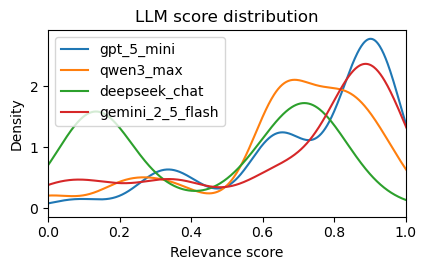

In [8]:
def kde(df):
    plot_df = pd.DataFrame()
    for col in LLM_MODELS:
        plot_df[col] = df[f"{col}_score" ].apply(pd.to_numeric, errors="coerce")

    ax = plot_df.plot(kind="kde", figsize=(4.5, 2.8), xlim=(0, 1))
    ax.set_xlabel("Relevance score")
    ax.set_ylabel("Density")
    ax.set_title("LLM score distribution")
    plt.tight_layout()
    plt.savefig(FIGURES/'llms-density.pdf',bbox_inches='tight')
    plt.show()
kde(origindf)

## 8. Box plots by expert label
Retain the manuscript's four-panel figure and original dimensions.

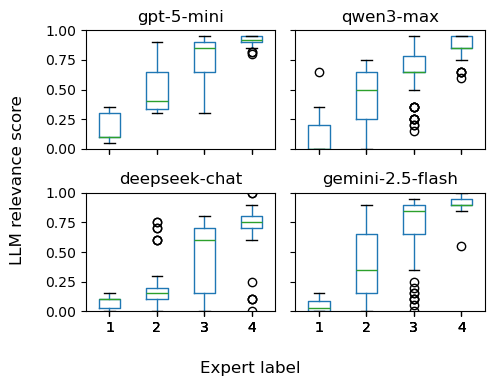

(<Figure size 500x400 with 4 Axes>,
 array([<Axes: title={'center': 'gpt-5-mini'}>,
        <Axes: title={'center': 'qwen3-max'}>,
        <Axes: title={'center': 'deepseek-chat'}>,
        <Axes: title={'center': 'gemini-2.5-flash'}>], dtype=object))

In [9]:
def boxplot_by_expert_label(df, size=(5, 4), save_path=None):
    plot_df = pd.DataFrame()

    plot_df["expert_label"] = df["final_label"].astype(int)

    for col in LLM_MODELS:
        plot_df[col] = pd.to_numeric(df[f"{col}_score"], errors="coerce")

    fig, axes = plt.subplots(
        2,
        2,
        figsize=size,
        sharex=True,
        sharey=True,
    )

    axes = axes.ravel()

    for ax, col in zip(axes, LLM_MODELS):
        plot_df.boxplot(
            column=col,
            by="expert_label",
            ax=ax,
            grid=False,
        )

        ax.set_title(LLM_DICT[col])
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_ylim(0, 1)

    for ax in axes[:2]:
        ax.tick_params(labelbottom=False)

    for ax in axes[[1, 3]]:
        ax.tick_params(labelleft=False)

    fig.suptitle("")
    fig.supxlabel("Expert label")
    fig.supylabel("LLM relevance score")

    fig.tight_layout()
    if save_path:
        plt.savefig(
            save_path,
            bbox_inches="tight",
        )
    plt.show()

    return fig, axes
boxplot_by_expert_label(origindf,save_path=FIGURES/'llms-box.pdf')

## 9. Confusion tables and count figure
Use one explicit 1-4 rubric, not an inferred zero-based label scheme. All inputs have already passed complete-cohort validation.

gpt-5-mini


Predicted label,1,2,3,4
Expert label,,,,
1,9,5,0,0
2,0,36,18,9
3,0,3,59,95
4,0,0,0,86


qwen3-max


Predicted label,1,2,3,4
Expert label,,,,
1,12,1,1,0
2,11,20,28,4
3,3,10,68,76
4,0,0,5,81


deepseek-chat


Predicted label,1,2,3,4
Expert label,,,,
1,14,0,0,0
2,48,8,5,2
3,56,14,67,20
4,4,1,23,58


gemini-2.5-flash


Predicted label,1,2,3,4
Expert label,,,,
1,14,0,0,0
2,22,18,11,12
3,8,16,33,100
4,0,0,1,85


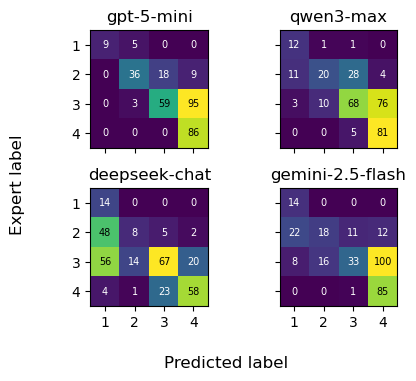

In [10]:
def get_expert_label(df):
    values = pd.to_numeric(df.final_label,errors='raise')
    if not values.isin([1,2,3,4]).all():
        raise ValueError('Expected expert labels 1..4.')
    return values.astype(int)
def score_to_label_1_4(score):
    value = float(score)
    if not np.isfinite(value) or not 0 <= value <= 1:
        raise ValueError('Expected finite score in [0,1].')
    return int(min(np.floor(value*4),3)+1)
def make_confusion_tables(df, model_keys):
    result = {}
    temp = df.copy()
    temp["expert_label"] = get_expert_label(temp)

    labels = [1, 2, 3, 4]

    for model_key in model_keys:
        score_col = f"{model_key}_score"
        pred_col = f"{model_key}_pred_label"

        temp[pred_col] = (
            pd.to_numeric(temp[score_col], errors="coerce")
            .apply(lambda x: score_to_label_1_4(x) if pd.notna(x) else np.nan)
            .astype("Int64")
        )

        valid = temp.dropna(subset=["expert_label", pred_col]).copy()

        table = pd.crosstab(
            valid["expert_label"],
            valid[pred_col],
            rownames=["Expert label"],
            colnames=["Predicted label"],
        ).reindex(index=labels, columns=labels, fill_value=0)

        row_norm = table.div(
            table.sum(axis=1).replace(0, np.nan),
            axis=0,
        )

        result[model_key] = {
            "count": table,
            "row_norm": row_norm,
        }

    return result

def plot_confusion_matrices(
    df,
    model_keys,
    normalize=False,
    figsize=(4.5, 3.8),
):
    temp = df.copy()
    temp["expert_label"] = get_expert_label(temp)

    labels = [1, 2, 3, 4]

    fig, axes = plt.subplots(
        2,
        2,
        figsize=figsize,
        sharex=True,
        sharey=True,
    )

    axes = axes.ravel()

    for ax, model_key in zip(axes, model_keys):
        score_col = f"{model_key}_score"
        pred_col = f"{model_key}_pred_label"

        temp[pred_col] = (
            pd.to_numeric(temp[score_col], errors="coerce")
            .apply(lambda x: score_to_label_1_4(x) if pd.notna(x) else np.nan)
            .astype("Int64")
        )

        valid = temp.dropna(subset=["expert_label", pred_col]).copy()

        cm = confusion_matrix(
            valid["expert_label"].astype(int),
            valid[pred_col].astype(int),
            labels=labels,
        )

        if normalize:
            row_sum = cm.sum(axis=1, keepdims=True)
            plot_cm = np.divide(
                cm,
                row_sum,
                out=np.zeros_like(cm, dtype=float),
                where=row_sum != 0,
            )
        else:
            plot_cm = cm

        im = ax.imshow(plot_cm, cmap='viridis', vmin=0,
                       vmax=1 if normalize else None)

        ax.set_title(LLM_DICT[model_key])
        ax.set_xticks(range(4))
        ax.set_yticks(range(4))
        ax.set_xticklabels(labels)
        ax.set_yticklabels(labels)

        for i in range(4):
            for j in range(4):
                if normalize:
                    text = f"{plot_cm[i, j]:.2f}"
                else:
                    text = str(cm[i, j])

                ax.text(
                    j,
                    i,
                    text,
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="white" if plot_cm[i, j] < (0.5 if normalize else plot_cm.max() / 2) else "black",
                )

    for ax in axes[:2]:
        ax.tick_params(labelbottom=False)

    for ax in axes[[1, 3]]:
        ax.tick_params(labelleft=False)

    fig.supxlabel("Predicted label")
    fig.supylabel("Expert label")

    fig.tight_layout()
    plt.show()

    return fig, axes
conf_tables = make_confusion_tables(origindf,LLM_MODELS)
for model,tables in conf_tables.items():
    for kind,t in tables.items():
        save_csv(t.reset_index(),LLM_OUTPUT/f'{model}_confusion_{kind}.csv')
    print(LLM_DICT[model])
    display(tables['count'])
fig,axes = plot_confusion_matrices(origindf,LLM_MODELS,normalize=False)
fig.savefig(FIGURES/'llms-confusion-count.pdf',bbox_inches='tight')

## 10. Row-normalized confusion figure
Show prediction proportions conditional on each expert-label level.

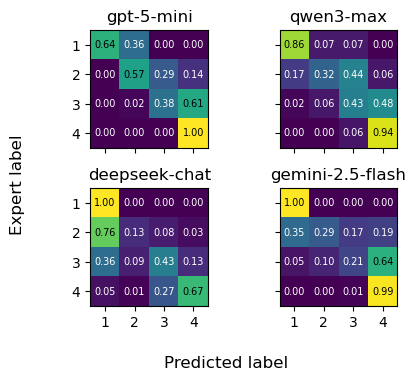

In [11]:
fig,axes = plot_confusion_matrices(origindf,LLM_MODELS,normalize=True)
fig.savefig(FIGURES/'llms-confusion-normalized.pdf',bbox_inches='tight')

## 11. Ordinal error summary
Separate exact agreement, one-level differences and errors of two or more levels.

In [12]:
rows = []
for model in LLM_MODELS:
    error = np.abs(ordinal(origindf[f'{model}_score'])-origindf.final_label.to_numpy(int))
    rows.append({'model':LLM_DICT[model],'n':len(error),'mean_ordinal_error':error.mean(),
        'median_ordinal_error':np.median(error),'exact_match_rate':(error==0).mean(),
        'within_one_label_rate':(error<=1).mean(),'severe_error_rate':(error>=2).mean()})
ordinal_error_df = pd.DataFrame(rows)
save_csv(ordinal_error_df,LLM_OUTPUT/'ordinal_error_summary.csv')
display(ordinal_error_df.round(4))

,model,n,mean_ordinal_error,median_ordinal_error,exact_match_rate,within_one_label_rate,severe_error_rate
0,gpt-5-mini,320,0.4344,0.0,0.5938,0.9719,0.0281
1,qwen3-max,320,0.4594,0.0,0.5656,0.9750,0.0250
2,deepseek-chat,320,0.7500,1.0,0.4594,0.8031,0.1969
3,gemini-2.5-flash,320,0.5938,1.0,0.4688,0.9375,0.0625


## 12. Supplementary fusion diagnostic
Retain the old alpha=0.5 diagnostic, explicitly separate from the manuscript's selected alpha=0.2.

In [13]:
base = metrics(origindf.final_label,origindf.cross_score)
rows = [{'score':'Cross-encoder only',**dict(zip(METRICS,base)),'delta_over_cross_spearman':0.0}]
for model in LLM_MODELS:
    result = metrics(origindf.final_label,.5*origindf.cross_score+.5*origindf[f'{model}_score'])
    rows.append({'score':f'Cross + {LLM_DICT[model]}',**dict(zip(METRICS,result)),
        'delta_over_cross_spearman':result[0]-base[0]})
fused_alignment_df = pd.DataFrame(rows)
save_csv(fused_alignment_df,LLM_OUTPUT/'diagnostic_alpha_0.5.csv')
display(fused_alignment_df.round(4))

,score,spearman,mae,qwk,delta_over_cross_spearman
0,Cross-encoder only,0.4835,0.2617,0.3981,0.0000
1,Cross + gpt-5-mini,0.6663,0.1386,0.6633,0.1828
2,Cross + qwen3-max,0.6311,0.1595,0.6156,0.1477
3,Cross + deepseek-chat,0.6559,0.1992,0.5017,0.1725
4,Cross + gemini-2.5-flash,0.6602,0.1576,0.6277,0.1767


## 13. Aggregation-weight scan and table
Scan alpha=0,0.1,...,1 on the fixed GPT-5-mini scores. This is same-subset calibration, not independent parameter evaluation.

In [14]:
def get_table(df):
    rows = []
    for k in range(11):
        alpha = k / 10
        fused = (
            alpha * df["cross_score"]
            + (1 - alpha) * df["gpt_5_mini_score"]
        )

        predicted_label = np.digitize(
            fused, bins=[0.25, 0.50, 0.75]
        ) + 1

        rows.append({
            "alpha": alpha,
            "Spearman": spearmanr(fused, df["final_score"]).statistic,
            "MAE": mean_absolute_error(df["final_score"], fused),
            "QWK": cohen_kappa_score(
                df["final_label"], predicted_label, weights="quadratic"
            ),
        })

    return pd.DataFrame(rows)
    

table = get_table(origindf)
save_csv(table, WEIGHT_OUTPUT / 'alpha_scan.csv')
display(table.round(4))

,alpha,Spearman,MAE,QWK
0,0.0,0.7671,0.1362,0.6722
1,0.1,0.7785,0.1202,0.6920
2,0.2,0.7621,0.1144,0.7272
3,0.3,0.7366,0.1148,0.7340
4,0.4,0.7030,0.1234,0.7177
5,0.5,0.6663,0.1386,0.6633
6,0.6,0.6241,0.1585,0.6241
7,0.7,0.5865,0.1815,0.5229
8,0.8,0.5547,0.2064,0.4558
9,0.9,0.5261,0.2335,0.4277


In [15]:
scan_latex = table.to_latex(
    index=False,
    formatters={
        "alpha": lambda x: f"{x:.1f}",
        "Spearman": lambda x: f"{x:.3f}",
        "MAE": lambda x: f"{x:.3f}",
        "QWK": lambda x: f"{x:.3f}",
    }
)
(WEIGHT_OUTPUT / 'alpha_scan.tex').write_text(scan_latex, encoding='utf-8')
print(scan_latex)

\begin{tabular}{rrrr}
\toprule
alpha & Spearman & MAE & QWK \\
\midrule
0.0 & 0.767 & 0.136 & 0.672 \\
0.1 & 0.778 & 0.120 & 0.692 \\
0.2 & 0.762 & 0.114 & 0.727 \\
0.3 & 0.737 & 0.115 & 0.734 \\
0.4 & 0.703 & 0.123 & 0.718 \\
0.5 & 0.666 & 0.139 & 0.663 \\
0.6 & 0.624 & 0.159 & 0.624 \\
0.7 & 0.587 & 0.182 & 0.523 \\
0.8 & 0.555 & 0.206 & 0.456 \\
0.9 & 0.526 & 0.234 & 0.428 \\
1.0 & 0.483 & 0.262 & 0.398 \\
\bottomrule
\end{tabular}



## 14. Aggregation-weight figure
Preserve the three metric curves and selected alpha=0.2 marker.

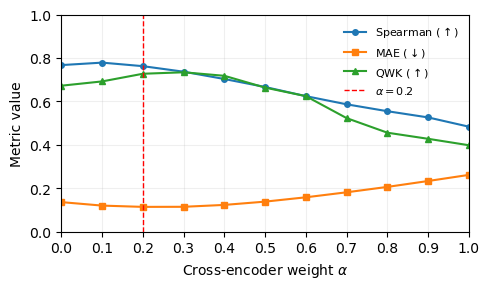

In [16]:
def line(results, size=(5, 3), save_path=None):
    

    fig, ax = plt.subplots(figsize=size)

    ax.plot(
        results["alpha"],
        results["Spearman"],
        marker="o",
        linewidth=1.5,
        markersize=4,
        label=r"Spearman ($\uparrow$)",
    )

    ax.plot(
        results["alpha"],
        results["MAE"],
        marker="s",
        linewidth=1.5,
        markersize=4,
        label=r"MAE ($\downarrow$)",
    )

    ax.plot(
        results["alpha"],
        results["QWK"],
        marker="^",
        linewidth=1.5,
        markersize=4,
        label=r"QWK ($\uparrow$)",
    )

    ax.axvline(
        0.2,
        color="red",
        linestyle="--",
        linewidth=1,
        label=r"$\alpha=0.2$",
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks(results["alpha"])
    ax.set_xlabel(r"Cross-encoder weight $\alpha$")
    ax.set_ylabel("Metric value")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)

    fig.tight_layout()
    if save_path:
        plt.savefig(
            save_path,
            bbox_inches="tight",
        )
line(table,save_path=FIGURES/'weight.pdf')
plt.show()

## 15. Fixed-weight intervals and paired differences
Compare alpha=0.2 with GPT-5-mini alone and neighboring weights. These intervals do not account for selecting the fixed weight.

In [17]:
cross = origindf.cross_score.to_numpy(float)
gpt = origindf.gpt_5_mini_score.to_numpy(float)
fixed_predictions = {
    'fixed_alpha_0.2_gpt5_mini': 0.2 * cross + 0.8 * gpt,
    'gpt5_mini': gpt,
    'fixed_alpha_0.1_gpt5_mini': 0.1 * cross + 0.9 * gpt,
    'fixed_alpha_0.3_gpt5_mini': 0.3 * cross + 0.7 * gpt,
}
fixed_pairs = [('fixed_alpha_0.2_gpt5_mini', name)
               for name in fixed_predictions if name != 'fixed_alpha_0.2_gpt5_mini']
fixed_metrics = report_scores(origindf, fixed_predictions, WEIGHT_OUTPUT, 'fixed_weight',
                              N_BOOT, SEED, pairs=fixed_pairs)
fixed_rows = origindf[['instance_id', 'citing_corpus_id', 'cited_corpus_id',
                       'field', 'score_bucket', 'final_label', 'final_score']].copy()
for name, values in fixed_predictions.items():
    fixed_rows[name] = values
save_csv(fixed_rows, WEIGHT_OUTPUT / 'fixed_weight_predictions.csv')
display(summary_table(fixed_metrics))
fixed_differences = pd.read_csv(WEIGHT_OUTPUT / 'fixed_weight_paired_differences.csv')
display(fixed_differences[['model_b', 'metric', 'difference_a_minus_b',
                           'ci_low', 'ci_high', 'excludes_zero']].round(4))

metric,model,spearman,mae,qwk
0,fixed_alpha_0.1_gpt5_mini,"0.778 [0.728, 0.823]","0.120 [0.108, 0.133]","0.692 [0.624, 0.752]"
1,fixed_alpha_0.2_gpt5_mini,"0.762 [0.707, 0.809]","0.114 [0.104, 0.125]","0.727 [0.663, 0.782]"
2,fixed_alpha_0.3_gpt5_mini,"0.737 [0.677, 0.789]","0.115 [0.105, 0.126]","0.734 [0.671, 0.784]"
3,gpt5_mini,"0.767 [0.718, 0.814]","0.136 [0.123, 0.150]","0.672 [0.600, 0.736]"


,model_b,metric,difference_a_minus_b,ci_low,ci_high,excludes_zero
0,gpt5_mini,spearman,-0.0049,-0.0406,0.0269,False
1,gpt5_mini,mae,-0.0219,-0.0288,-0.0141,True
2,gpt5_mini,qwk,0.0550,0.0223,0.0883,True
3,fixed_alpha_0.1_gpt5_mini,spearman,-0.0163,-0.0303,-0.0034,True
4,fixed_alpha_0.1_gpt5_mini,mae,-0.0059,-0.0099,-0.0015,True
5,fixed_alpha_0.1_gpt5_mini,qwk,0.0353,0.0076,0.0646,True
6,fixed_alpha_0.3_gpt5_mini,spearman,0.0255,0.0142,0.0390,True
7,fixed_alpha_0.3_gpt5_mini,mae,-0.0004,-0.0045,0.0036,False
8,fixed_alpha_0.3_gpt5_mini,qwk,-0.0068,-0.0375,0.0238,False


## 16. Training-fold selection and held-out evaluation
Five grouped folds repeated five times use SEED,...,SEED+4. Select the LLM or LLM-alpha pair on training data only, then evaluate complete held-out predictions. Average metrics across repetitions, not repeated instances.

In [18]:
cv_predictions, selections = cross_validate_selection(
    origindf, WEIGHT_OUTPUT, n_splits=N_SPLITS, repeats=REPEATS, seed=SEED)
cv_metrics = report_scores(
    origindf, cv_predictions, WEIGHT_OUTPUT, 'selection_cv', N_BOOT, SEED,
    pairs=[('selected_fusion', 'selected_llm'), ('selected_fusion', 'fixed_gpt5_mini')])
display(summary_table(cv_metrics))
display(pd.read_csv(WEIGHT_OUTPUT / 'selection_cv_paired_differences.csv')[
    ['model_a', 'model_b', 'metric', 'difference_a_minus_b', 'ci_low', 'ci_high',
     'excludes_zero']].round(4))
display(pd.read_csv(WEIGHT_OUTPUT / 'fusion_selection_frequency.csv'))
display(pd.read_csv(WEIGHT_OUTPUT / 'per_repetition_metrics.csv').round(4))

metric,model,spearman,mae,qwk
0,fixed_gpt5_mini,"0.767 [0.718, 0.814]","0.136 [0.123, 0.150]","0.672 [0.600, 0.736]"
1,selected_fusion,"0.778 [0.728, 0.823]","0.120 [0.108, 0.133]","0.692 [0.624, 0.752]"
2,selected_llm,"0.744 [0.692, 0.790]","0.135 [0.122, 0.148]","0.673 [0.603, 0.734]"


,model_a,model_b,metric,difference_a_minus_b,ci_low,ci_high,excludes_zero
0,selected_fusion,selected_llm,spearman,0.0340,0.0091,0.0573,True
1,selected_fusion,selected_llm,mae,-0.0146,-0.0180,-0.0109,True
2,selected_fusion,selected_llm,qwk,0.0188,0.0023,0.0376,True
3,selected_fusion,fixed_gpt5_mini,spearman,0.0114,-0.0137,0.0342,False
4,selected_fusion,fixed_gpt5_mini,mae,-0.0160,-0.0195,-0.0123,True
5,selected_fusion,fixed_gpt5_mini,qwk,0.0197,0.0057,0.0385,True


,fusion_llm,alpha,fold_count
0,gpt_5_mini_score,0.1,25


,repeat,model,spearman,mae,qwk
0,0,selected_llm,0.7344,0.1337,0.6734
1,1,selected_llm,0.7671,0.1362,0.6722
2,2,selected_llm,0.7671,0.1362,0.6722
3,3,selected_llm,0.7356,0.1331,0.6831
4,4,selected_llm,0.7178,0.1347,0.6648
5,0,selected_fusion,0.7785,0.1202,0.6920
6,1,selected_fusion,0.7785,0.1202,0.6920
7,2,selected_fusion,0.7785,0.1202,0.6920
8,3,selected_fusion,0.7785,0.1202,0.6920
9,4,selected_fusion,0.7785,0.1202,0.6920


## 17. Manuscript calibration/held-out table
Keep same-subset and held-out rows explicitly distinct. Metric CSVs retain unrounded values.

In [19]:
for name,result in [('fixed_weight',fixed_metrics),('selection_cv',cv_metrics)]:
    compact = summary_table(result)
    save_csv(compact,WEIGHT_OUTPUT/f'{name}_table.csv')
    (WEIGHT_OUTPUT/f'{name}_table.tex').write_text(compact.to_latex(index=False),encoding='utf-8')
rows = []
for title,model,result in [
    ('Fixed alpha=0.2 / Same-subset','fixed_alpha_0.2_gpt5_mini',fixed_metrics),
    ('LLM selection / Held-out','selected_llm',cv_metrics),
    ('LLM-alpha selection / Held-out','selected_fusion',cv_metrics)]:
    selected = result.loc[result.model.eq(model)].set_index('metric')
    row = {'Protocol':title}
    for metric,label in [('spearman','Spearman'),('mae','MAE'),('qwk','QWK')]:
        r = selected.loc[metric]
        row[label] = rf'\shortstack{{{r.estimate:.3f}\\{{}}[{r.ci_low:.3f}, {r.ci_high:.3f}]}}'
    rows.append(row)
weight_paper_table = pd.DataFrame(rows)
save_csv(weight_paper_table,WEIGHT_OUTPUT/'weight_paper_table.csv')
weight_latex = weight_paper_table.to_latex(index=False,escape=False,column_format='lccc')
(WEIGHT_OUTPUT/'weight_paper_table.tex').write_text(weight_latex,encoding='utf-8')
display(weight_paper_table)
print(weight_latex)

,Protocol,Spearman,MAE,QWK
0,Fixed alpha=0.2 / Same-subset,"\shortstack{0.762\\{}[0.707, 0.809]}","\shortstack{0.114\\{}[0.104, 0.125]}","\shortstack{0.727\\{}[0.663, 0.782]}"
1,LLM selection / Held-out,"\shortstack{0.744\\{}[0.692, 0.790]}","\shortstack{0.135\\{}[0.122, 0.148]}","\shortstack{0.673\\{}[0.603, 0.734]}"
2,LLM-alpha selection / Held-out,"\shortstack{0.778\\{}[0.728, 0.823]}","\shortstack{0.120\\{}[0.108, 0.133]}","\shortstack{0.692\\{}[0.624, 0.752]}"


\begin{tabular}{lccc}
\toprule
Protocol & Spearman & MAE & QWK \\
\midrule
Fixed alpha=0.2 / Same-subset & \shortstack{0.762\\{}[0.707, 0.809]} & \shortstack{0.114\\{}[0.104, 0.125]} & \shortstack{0.727\\{}[0.663, 0.782]} \\
LLM selection / Held-out & \shortstack{0.744\\{}[0.692, 0.790]} & \shortstack{0.135\\{}[0.122, 0.148]} & \shortstack{0.673\\{}[0.603, 0.734]} \\
LLM-alpha selection / Held-out & \shortstack{0.778\\{}[0.728, 0.823]} & \shortstack{0.120\\{}[0.108, 0.133]} & \shortstack{0.692\\{}[0.624, 0.752]} \\
\bottomrule
\end{tabular}



## 18. Controlled abstract-only calibration and figure
Use the same complete-context pairs with citing abstracts replacing contexts. Scan the exact 0.50,...,1.00 grid with the original normalized MAE/QWK joint-distance criterion. This does not validate naturally missing cases.

Selected lambda: 0.95
Spearman: 0.3469
MAE: 0.1750
QWK: 0.3476
Distance to ideal: 0.0112


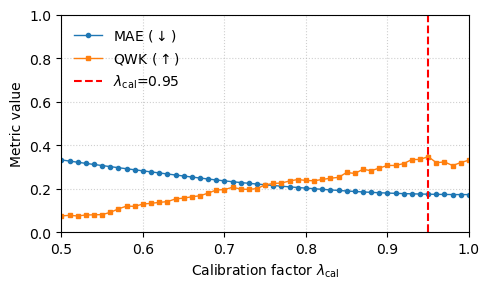

In [20]:
def calibrate_lambda(merged_df, show_plot=True, size=(5, 3), save_path=None):

    alpha = ALPHA

    expert_label = (
        merged_df["final_label"]
        .astype(int)
        .to_numpy()
    )

    expert_score = merged_df["final_score"]

    abstract_score = (
        alpha
        * merged_df["cross_abstract_score"].to_numpy()
        + (1 - alpha)
        * merged_df["gpt_5_mini_abstract_score"].to_numpy()
    )

    rows = []

    for lambda_value in np.arange(50,101)/100:

        penalized_score = (
            lambda_value * abstract_score
        )

        predicted_label = np.clip(
            np.floor(penalized_score * 4) + 1,
            1,
            4,
        ).astype(int)

        mae = mean_absolute_error(
            expert_score,
            penalized_score,
        )

        qwk = cohen_kappa_score(
            expert_label,
            predicted_label,
            weights="quadratic",
        )

        rows.append(
            {
                "lambda": round(lambda_value, 2),
                "mae": mae,
                "qwk": qwk,
            }
        )

    lambda_df = pd.DataFrame(rows)


    mae_min = lambda_df["mae"].min()
    mae_max = lambda_df["mae"].max()

    qwk_min = lambda_df["qwk"].min()
    qwk_max = lambda_df["qwk"].max()


    lambda_df["mae_loss"] = (
        lambda_df["mae"] - mae_min
    ) / (
        mae_max - mae_min + 1e-12
    )


    lambda_df["qwk_loss"] = (
        qwk_max - lambda_df["qwk"]
    ) / (
        qwk_max - qwk_min + 1e-12
    )


    lambda_df["distance_to_ideal"] = np.sqrt(
        lambda_df["mae_loss"] ** 2
        + lambda_df["qwk_loss"] ** 2
    )


    best_index = (
        lambda_df["distance_to_ideal"]
        .idxmin()
    )

    best_result = lambda_df.loc[
        best_index
    ]

    selected_lambda = float(
        best_result["lambda"]
    )

    lambda_df["selected"] = (
        lambda_df["lambda"]
        == selected_lambda
    )

    rho = spearmanr(
        expert_score,
        abstract_score,
    ).statistic

    print(f"Selected lambda: {selected_lambda:.2f}")
    print(f"Spearman: {rho:.4f}")
    print(f"MAE: {best_result['mae']:.4f}")
    print(f"QWK: {best_result['qwk']:.4f}")
    print(
        "Distance to ideal:",
        f"{best_result['distance_to_ideal']:.4f}",
    )

    if show_plot:

        fig, ax = plt.subplots(
            figsize=size
        )
        

        ax.plot(
            lambda_df["lambda"],
            lambda_df["mae"],
            marker="o",
            markersize=3,
            linewidth=1,
            label=r"MAE ($\downarrow$)"
        )


        ax.plot(
            lambda_df["lambda"],
            lambda_df["qwk"],
            marker="s",
            markersize=3,
            linewidth=1,
            label=r"QWK ($\uparrow$)"
        )

        ax.axvline(
            selected_lambda,
            color="red",
            linestyle="--",
            linewidth=1.5,
            label=(
                r"$\lambda_{\mathrm{cal}}$"
                f"={selected_lambda:.2f}"
            ),
        )


        ax.set_xlabel(
            r"Calibration factor $\lambda_{\mathrm{cal}}$"
        )

        ax.set_ylabel(
            "Metric value"
        )

        ax.set_xlim(
            0.5,
            1.0,
        )

        ax.set_ylim(
            0.0,
            1.0,
        )

        ax.grid(
            linestyle=":",
            alpha=0.6,
        )

        ax.legend(
            frameon=False
        )

        plt.tight_layout()
        if save_path:
            plt.savefig(
                save_path,
                bbox_inches="tight",
            )
        plt.show()

    return lambda_df
lambda_df = calibrate_lambda(merged_df,save_path=FIGURES/'calibration.pdf')
save_csv(lambda_df,PENALTY_OUTPUT/'lambda_scan.csv')

## 19. Selected factors and design discount
The additional 0.8 discount is a configurable design choice, not another calibrated optimum. Preserve one-decimal rounding for the final coefficient.

In [21]:
selected_factors = lambda_df.loc[lambda_df['lambda'].isin([.80,.90,.95,1.00]),
    ['lambda','mae','qwk','distance_to_ideal']].copy()
save_csv(selected_factors,PENALTY_OUTPUT/'selected_lambda_factors.csv')
latex = selected_factors.to_latex(index=False,float_format=lambda x:f'{x:.4f}')
(PENALTY_OUTPUT/'selected_lambda_factors.tex').write_text(latex,encoding='utf-8')
display(selected_factors)
lambda_cal = float(lambda_df.loc[lambda_df.selected,'lambda'].iloc[0])
final_lambda = float(Decimal(str(lambda_cal*DESIGN_DISCOUNT)).quantize(Decimal('0.1'),rounding=ROUND_HALF_UP))
if not 0 < DESIGN_DISCOUNT < 1 or not 0 < final_lambda < lambda_cal:
    raise ValueError('Final penalty must be positive and below the calibration factor.')
print(f'Calibration={lambda_cal:.2f}; design discount={DESIGN_DISCOUNT:.2f}; rounded final lambda={final_lambda:.1f}')

,lambda,mae,qwk,distance_to_ideal
30,0.80,0.202867,0.238095,0.442954
40,0.90,0.180275,0.306997,0.155529
45,0.95,0.175012,0.347628,0.011211
50,1.00,0.173263,0.331288,0.059961


Calibration=0.95; design discount=0.80; rounded final lambda=0.8


## 20. Paired abstract-minus-context differences
Report minimum, maximum, median and all tied modes of unpenalized differences. Exact continuous values may have no repeated mode; rounded modes use two decimal places, explicitly labeled. These summaries do not redefine the penalty.

In [22]:
def summarize_paired_differences(differences, mode_decimals=2):
    """Describe signed paired differences, retaining every tied mode."""
    values = pd.to_numeric(pd.Series(differences), errors="raise").astype(float)
    if values.empty or not np.isfinite(values.to_numpy()).all():
        raise ValueError("Differences must be nonempty, finite and complete.")
    summary = {
        "n": len(values), "minimum": float(values.min()),
        "maximum": float(values.max()), "median": float(values.median()),
    }
    frequencies = []
    for kind, grouped in [
        ("exact", values), ("rounded", values.round(mode_decimals)),
    ]:
        counts = grouped.value_counts().sort_index()
        frequency = int(counts.max())
        modes = counts.index[counts == frequency].tolist()
        summary[f"{kind}_modes"] = json.dumps(modes if frequency > 1 else [])
        summary[f"{kind}_mode_count"] = frequency
        for value, count in counts.items():
            frequencies.append({
                "grouping": kind, "difference": float(value),
                "count": int(count),
                "is_mode": bool(frequency > 1 and count == frequency),
            })
    return pd.DataFrame([summary]), pd.DataFrame(frequencies)
normal = ALPHA*origindf.cross_score+(1-ALPHA)*origindf.gpt_5_mini_score
abstract = ALPHA*origindf.cross_abstract_score+(1-ALPHA)*origindf.gpt_5_mini_abstract_score
paired_scores = origindf[['instance_id']+PAIR].copy()
paired_scores['normal_score'],paired_scores['abstract_score'] = normal,abstract
paired_scores['difference'] = abstract-normal
difference_summary,mode_frequencies = summarize_paired_differences(paired_scores.difference)
save_csv(paired_scores,PENALTY_OUTPUT/'scores.csv')
save_csv(difference_summary,PENALTY_OUTPUT/'summary.csv')
save_csv(mode_frequencies,PENALTY_OUTPUT/'mode_frequencies.csv')
display(difference_summary)
print('Difference = unpenalized abstract minus context; [] means no repeated exact mode.')

,n,minimum,maximum,median,exact_modes,exact_mode_count,rounded_modes,rounded_mode_count
0,320,-0.679337,0.655921,-0.106255,[],1,"[-0.21, -0.03, -0.01]",9


Difference = unpenalized abstract minus context; [] means no repeated exact mode.


## 21. Reproducibility manifest
Record input/code hashes, packages, seeds and settings. Analysis run time is not a collection/inference date. Database scored_at denotes the latest derived-score row update, not the inference date of each model field.

In [23]:
version = subprocess.run(['git','rev-parse','HEAD'],cwd=SRC_DIR,capture_output=True,text=True)
packages = {}
for name in ['numpy','pandas','scipy','scikit-learn','matplotlib','openpyxl','python-dotenv']:
    try:
        packages[name] = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        pass
nb_code = [c['source'] for c in json.loads((SRC_DIR/'expert_evaluation.ipynb').read_text(encoding='utf-8'))['cells']
           if c['cell_type']=='code']
record = {
    'analysis_run_utc':datetime.now(timezone.utc).isoformat(),
    'git_commit_at_run':version.stdout.strip(),
    'analysis_code_sha256':hashlib.sha256(json.dumps(nb_code,ensure_ascii=False).encode()).hexdigest(),
    'inputs':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [LABEL_INPUT,LLM_INPUT,ABSTRACT_INPUT]},
    'packages':packages,'n_human_labels':len(origindf),'rows_dropped':0,
    'base_seed':SEED,'split_seeds':list(range(SEED,SEED+REPEATS)),
    'llm_pair_bootstrap_seeds':list(range(SEED+1,SEED+7)),
    'bootstrap_draws':N_BOOT,'folds':N_SPLITS,'repetitions':REPEATS,
    'bootstrap_unit':'connected shared-paper component in either citation role',
    'interval_scope':'95% percentile, conditional on saved predictions; no bootstrap reselection',
    'paired_intervals':'exploratory, unadjusted for multiplicity',
    'label_to_score':'(label-.5)/4','ordinal_cutpoints':[.25,.5,.75],
    'alpha_grid':ALPHA_GRID.tolist(),'selected_alpha':ALPHA,
    'lambda_grid':(np.arange(50,101)/100).tolist(),'lambda_cal':lambda_cal,
    'design_discount':DESIGN_DISCOUNT,'final_lambda':final_lambda,
    'difference':'unpenalized abstract minus context','mode_rounding':'two decimals, half-to-even',
    'source_timestamps':timestamp_table.to_dict(orient='records'),
    'data_collection':'July 2026 (reported collection period)',
    'new_model_calls':0,'database_reads':0,'database_writes':0}
(OUTPUT_ROOT/'manifest.json').write_text(json.dumps(record,indent=2),encoding='utf-8')
print(f'Completed. Stable derived outputs: {OUTPUT_ROOT}')

Completed. Stable derived outputs: D:\thales\must\ref-quantified\src\sample\expert_evaluation
